# PCB 한 장의 정상·불량 판정
DeepPCB → DeepPCB + PKU → DeepPCB + PKU + VisA PCB1~PCB4로 학습 출처를 넓힐 때, 같은 시험 원본에서 불량 검출과 정상 오탐이 어떻게 변하는지 살펴본다. 양성은 **1 defect**, 음성은 **0 normal**이다. 주석은 타일 라벨과 육안 검증에 사용한다.

아래 셀은 저장된 분할, 학습 로그, validation과 test 예측을 읽는다. 결과가 없는 단계에서는 먼저 실행할 명령을 표시한다.

In [1]:
from pathlib import Path
import sys

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as InlineImage, Markdown, display
from PIL import Image, ImageDraw

# deeppcb, src2 또는 PyCharm 프로젝트 루트에서 열 수 있다.
start = Path.cwd().resolve()
locations = [p / suffix for p in (start, *start.parents)
             for suffix in ("src2/config.json", "data_example/DeepPCB/deeppcb/src2/config.json")]
CONFIG = next((p for p in locations if p.is_file()), None)
if CONFIG is None:
    raise FileNotFoundError("deeppcb 폴더에서 열거나 CONFIG에 src2/config.json의 절대 경로를 지정하세요.")
PROJECT = CONFIG.parent.parent
sys.path.insert(0, str(PROJECT))
from src2.common import SPLITS, config, load_prepared, read_json, sha256

# 다른 실험을 보려면 여기에 그 설정 파일을 지정한다.
CONFIG = CONFIG.parent / "config.json"
DETAIL_MODE = "operating"   # "default"는 임계값 0.5
ERROR_MODEL = "C"
cfg = config(CONFIG)
output = Path(cfg["output_dir"])
prepared = output / "prepared"
run_root = output / "runs"
has_data = (prepared / "summary.json").is_file()
if has_data:
    _, originals, tiles, report = load_prepared(cfg)
    counts = pd.DataFrame(report["counts"])

models = [m for m in "ABC" if (run_root / m / "run.json").is_file()]
info = {m: read_json(run_root / m / "run.json") for m in models}
if len({v["protocol_id"] for v in info.values()}) > 1:
    raise ValueError("실험 조건이 다른 모델이 섞였습니다. 같은 설정으로 만든 결과를 선택하세요.")
if has_data and any(v["manifest_sha256"] != report["manifest_sha256"] for v in info.values()):
    raise ValueError("모델 학습 때와 현재 원본·타일 목록이 다릅니다.")
tested = [m for m in models if (run_root / m / "test/evaluation.json").is_file()]

plt.rcParams.update({"figure.dpi": 105, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
colors = {"A": "#315580", "B": "#b55a10", "C": "#007966"}
def table(frame):
    display(frame.style.format(precision=3, na_rep="—").hide(axis="index"))
def read_frame(path):
    return pd.read_csv(path, dtype={"board": str})
def command(step):
    return f"python -m src2.{dict(prepare='01_prepare', train='02_train', evaluate='03_evaluate')[step]} --config \"{CONFIG}\""
if not has_data:
    print("원본과 타일 목록을 먼저 만드세요.", command("prepare"))
if set(models) != set("ABC"):
    print("학습 결과가 필요한 실험", sorted(set("ABC") - set(models)), command("train"))
if set(tested) != set("ABC"):
    print("학습 완료 후 최종 평가", command("evaluate"))

## 실행 요약

In [2]:
if has_data:
    display(Markdown(f"원본 **{len(originals):,}장**에서 창 **{len(tiles):,}개**를 만들었다. "
                     f"부분 겹침으로 타일 지도학습에서 제외한 창은 **{(tiles.label == -1).sum():,}개**다."))
if tested:
    test_reports = {m: read_json(run_root / m / "test/evaluation.json") for m in tested}
    if len({r["test_ids_sha256"] for r in test_reports.values()}) != 1:
        raise ValueError("모델 간 test 원본 ID가 다릅니다.")
    for m, r in test_reports.items():
        if any(sha256(run_root / m / "test" / name) != digest for name, digest in r["files"].items()):
            raise ValueError(f"{m}의 저장된 시험 결과가 변경되었습니다.")
    final = pd.concat([read_frame(run_root / m / "test/metrics.csv").assign(model=m) for m in tested],
                      ignore_index=True)
    overall = final[final.scope == "all"]
    compact = overall[overall["mode"] == DETAIL_MODE]
    display(Markdown(f"공통 test **{int(compact.iloc[0]['n']):,}장**, "
                     f"아래 표는 **{DETAIL_MODE}** 임계값의 원본 이미지 결과다."))
    table(compact[["model", "threshold", "tp", "fn", "fp", "recall", "fpr", "pr_auc"]])
    if "C" in tested:
        c = overall[overall.model == "C"].set_index("mode")
        print(f"C에서 기본 0.5의 오탐 {c.loc['default', 'fp']}장·미검출 {c.loc['default', 'fn']}장, "
              f"검증에서 고른 운영 임계값의 오탐 {c.loc['operating', 'fp']}장·미검출 {c.loc['operating', 'fn']}장.")
else:
    print("확정된 시험 지표가 없습니다.", command("evaluate"))

원본 **8,119장**에서 창 **46,486개**를 만들었다. 부분 겹침으로 타일 지도학습에서 제외한 창은 **915개**다.

공통 test **1,216장**, 아래 표는 **operating** 임계값의 원본 이미지 결과다.

model,threshold,tp,fn,fp,recall,fpr,pr_auc
A,0.975,189,207,26,0.477,0.032,0.677
B,0.998,279,117,5,0.705,0.006,0.902
C,0.949,329,67,4,0.831,0.005,0.990


C에서 기본 0.5의 오탐 28장·미검출 15장, 검증에서 고른 운영 임계값의 오탐 4장·미검출 67장.


## 원본 데이터와 라벨

DeepPCB 검사 이미지는 TXT에 결함 박스가 있으면 불량이고 정상 템플릿은 정상이다. PKU의 이미지와 Pascal VOC XML은 상대 경로와 파일명, 원본 크기로 연결한다. VisA는 Normal과 Anomaly 폴더를 따르며, 이상 마스크의 0이 아닌 값을 전경으로 읽는다. 이 작업 공간에서 PKU XML 원본은 `out_data/PCB_DATASET`에 있고, 비슷한 이름의 `PCB-Defect An Annotated Dataset` 폴더는 별도 배포본이다.

[DeepPCB 공식 라벨](https://github.com/tangsanli5201/DeepPCB) · [PKU-Market-PCB](https://robotics.pkusz.edu.cn/resources/dataset/) · [VisA 원본 구조](https://github.com/amazon-science/spot-diff)

In [3]:
table(pd.DataFrame([{"source": s, "root": p, "directory_exists": Path(p).is_dir()}
                    for s, p in cfg["paths"].items()]))
if has_data:
    sample = originals.groupby(["source", "role"], sort=False).head(1).copy()
    sample["files_present"] = [
        (Path(cfg["paths"][r.source]) / r.path).is_file()
        and (not r.annotation or (Path(cfg["paths"][r.source]) / r.annotation).is_file())
        for r in sample.itertuples()]
    table(sample[["source", "role", "path", "annotation", "width", "height", "files_present"]])

source,root,directory_exists
DeepPCB,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\data,True
PKU,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\out_data\PCB_DATASET,True
VisA,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\out_data,True


source,role,path,annotation,width,height,files_present
DeepPCB,template,group00041/00041/00041000_temp.jpg,,640,640,True
DeepPCB,tested,group00041/00041/00041000_test.jpg,group00041/00041_not/00041000.txt,640,640,True
PKU,template,PCB_USED/01.JPG,,3034,1586,True
PKU,tested,images/Missing_hole/01_missing_hole_01.jpg,Annotations/Missing_hole/01_missing_hole_01.xml,3034,1586,True
VisA,anomaly,pcb1/Data/Images/Anomaly/000.JPG,pcb1/Data/Masks/Anomaly/000.png,1404,1070,True
VisA,normal,pcb1/Data/Images/Normal/0000.JPG,,1404,1070,True


In [4]:
if has_data:
    totals = counts.groupby("source", as_index=False)[
        ["original_normal", "original_defect", "all_tiles", "tile_normal", "tile_defect", "tile_excluded"]].sum()
    table(totals)
    visa = originals[originals.source == "VisA"]
    if not visa.empty:
        table(visa.groupby(["board", "label"]).size().unstack(fill_value=0)
              .rename(columns={0: "normal originals", 1: "defect originals"}).reset_index())
    print("공식 목록 밖의 파일과 기존 증강본", report["omitted"])

source,original_normal,original_defect,all_tiles,tile_normal,tile_defect,tile_excluded
DeepPCB,1500,1500,3000,1500,1500,0
PKU,10,693,16990,11856,4374,760
VisA,4016,400,26496,25156,1185,155


board,normal originals,defect originals
pcb1,1004,100
pcb2,1001,100
pcb3,1006,100
pcb4,1005,100


공식 목록 밖의 파일과 기존 증강본 {'DeepPCB_unlisted_images': ['group90100/90100/90100034_temp.jpg'], 'PKU_rotation_images': 693}


## 보드 그룹, 분할과 누수 검사

원본을 먼저 분할하고 그 안에서 타일을 만든다. 같은 DeepPCB 그룹과 PKU 보드 번호는 정상·불량을 함께 이동한다. VisA는 각 PCB 종류의 클래스별로 원본 ID를 배정한다. 증강은 학습 배치를 읽은 뒤 적용한다. 아래 그룹 수와 이미지 수는 실제 분할의 크기다.

In [5]:
if has_data:
    print("Seed", report["settings"]["seed"], "목표 train / validation / test", report["settings"]["split_fractions"])
    table(counts[["source", "split", "groups", "original_normal", "original_defect", "all_tiles",
                  "kept_tiles", "tile_excluded", "originals_with_kept_tiles", "defect_originals_without_positive_tile"]])
    boards = originals[originals.source.isin(["DeepPCB", "PKU"])]
    groups = boards.groupby(["source", "split"]).board.agg(lambda x: ", ".join(sorted(set(x))))
    table(groups.rename("board IDs").reset_index())
    if report["groups_missing_split"]:
        print("그룹 수 제약으로 비어 있는 구간", report["groups_missing_split"])
    print("같은 분할 내 바이트 중복 추가 파일", report["leakage"]["repeated_image_files_within_split"])
    table(pd.DataFrame(report["leakage"]["violations"].items(), columns=["누수·무결성 검사", "위반 건수"]))

Seed 42 목표 train / validation / test [0.7, 0.15, 0.15]


source,split,groups,original_normal,original_defect,all_tiles,kept_tiles,tile_excluded,originals_with_kept_tiles,defect_originals_without_positive_tile
DeepPCB,train,7,1004,1004,2008,2008,0,2008,0
DeepPCB,validation,3,280,280,560,560,0,560,0
DeepPCB,test,1,216,216,432,432,0,432,0
PKU,train,7,7,453,10676,10161,515,460,0
PKU,validation,1,1,120,3630,3527,103,121,0
PKU,test,2,2,120,2684,2542,142,122,0
VisA,train,3091,2811,280,18546,18444,102,3091,0
VisA,validation,663,603,60,3978,3951,27,663,0
VisA,test,662,602,60,3972,3946,26,662,0


source,split,board IDs
DeepPCB,test,group13000
DeepPCB,train,"group00041, group12300, group20085, group44000, group50600, group77000, group90100"
DeepPCB,validation,"group12000, group12100, group92000"
PKU,test,"05, 09"
PKU,train,"01, 06, 07, 08, 10, 11, 12"
PKU,validation,04


같은 분할 내 바이트 중복 추가 파일 2


누수·무결성 검사,위반 건수
image_id_in_multiple_splits,0
group_id_in_multiple_splits,0
sha256_in_multiple_splits,0
same_bytes_conflicting_labels,0
duplicate_original_id,0
duplicate_tile_id,0
repeated_tile_in_original,0
tile_parent_split_mismatch,0
originals_without_tiles,0


## 타일이 실제 결함을 포함하는지 확인

왼쪽 그림의 청록색 선은 원본에서 자른 창이고, 분홍색은 정답 박스 또는 마스크다. 가운데는 모델이 볼 타일의 원래 RGB 영상이며 오른쪽은 정답을 겹친 타일이다. 각 결함의 전체 박스 면적 또는 마스크 연결 성분 픽셀 수를 분모로 쓴다. 여러 결함 중 가장 큰 포함 비율을 기록한다. 겹침이 0이면 정상, 양수이면서 기준에 못 미치면 제외한다. 아래 예시는 학습 원본에서 골랐다.

타일 정책 {'size': 640, 'overlap': 128, 'min_defect_coverage': 0.5}


source,example,image_id,tile_id,overlap_px,region_px,overlap_fraction
DeepPCB,normal,DeepPCB/group00041/00041/00041000_temp.jpg,0,0,0,0.000
DeepPCB,defect,DeepPCB/group00041/00041/00041000_test.jpg,1,840,840,1.000
PKU,normal,PKU/PCB_USED/01.JPG,3000,0,0,0.000
PKU,defect,PKU/images/Missing_hole/01_missing_hole_01.jpg,3242,3276,4221,0.776
PKU,excluded,PKU/images/Missing_hole/01_missing_hole_02.jpg,3267,1265,2970,0.426
VisA,normal,VisA/pcb1/Data/Images/Normal/0000.JPG,20590,0,0,0.000
VisA,defect,VisA/pcb1/Data/Images/Anomaly/000.JPG,19993,1524,1524,1.000
VisA,excluded,VisA/pcb1/Data/Images/Anomaly/009.JPG,20047,387,4769,0.081


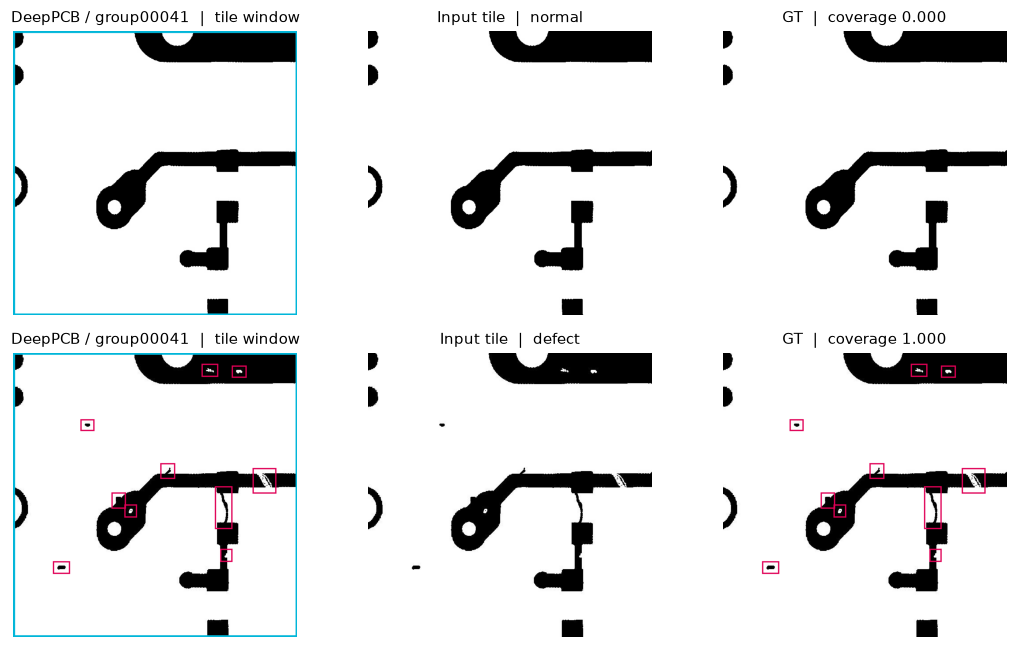

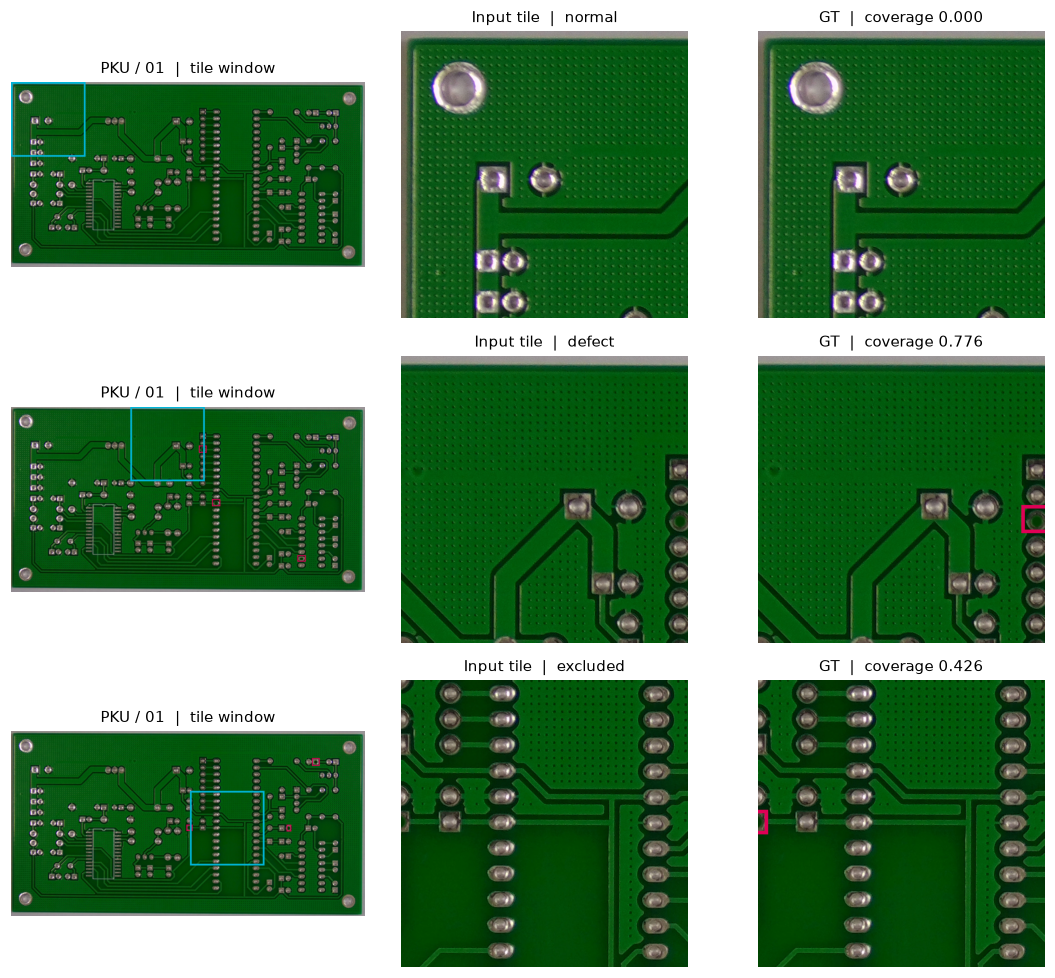

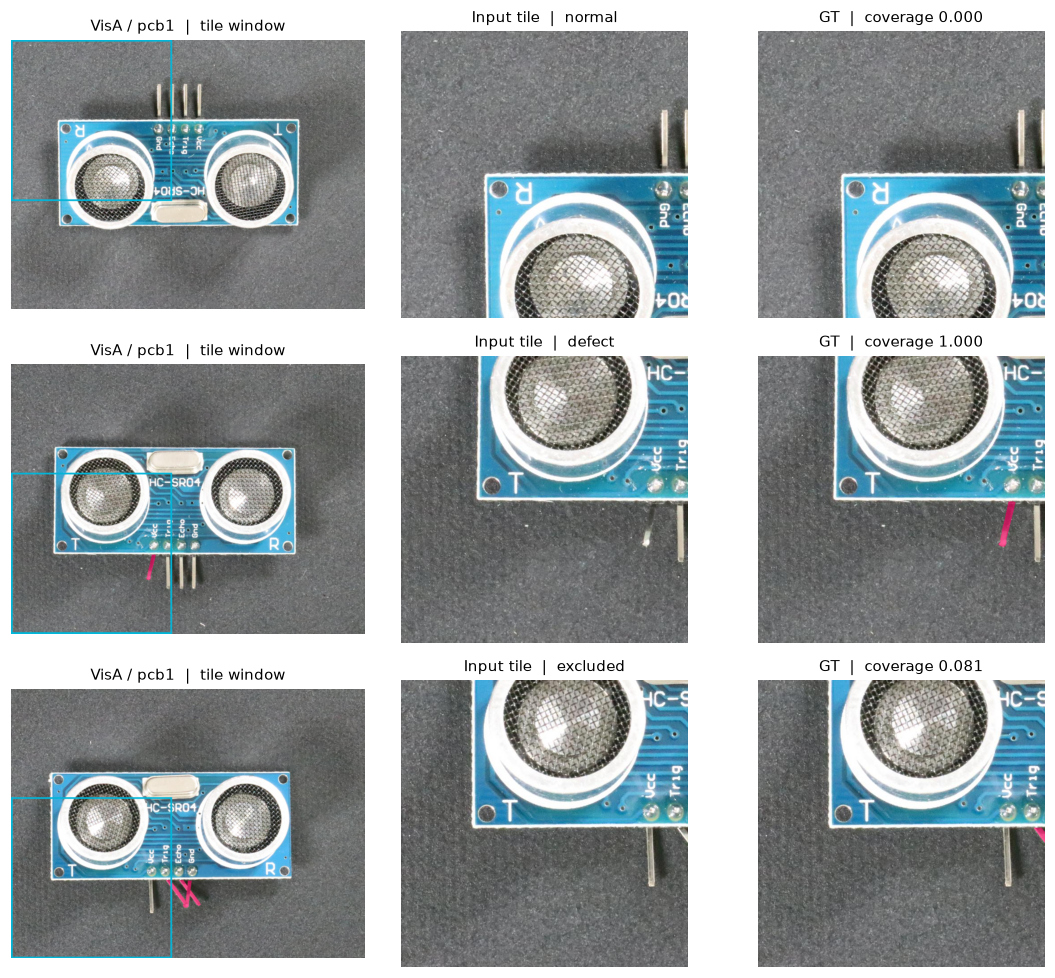

In [6]:
if has_data:
    print("타일 정책", report["settings"]["tiling"])
    examples = read_frame(prepared / "preview_examples.csv")
    table(examples[["source", "example", "image_id", "tile_id", "overlap_px", "region_px", "overlap_fraction"]])
    for source in cfg["sources"]:
        sample = prepared / "previews" / f"{source}.png"
        if sample.is_file():
            display(InlineImage(filename=str(sample), width=760))

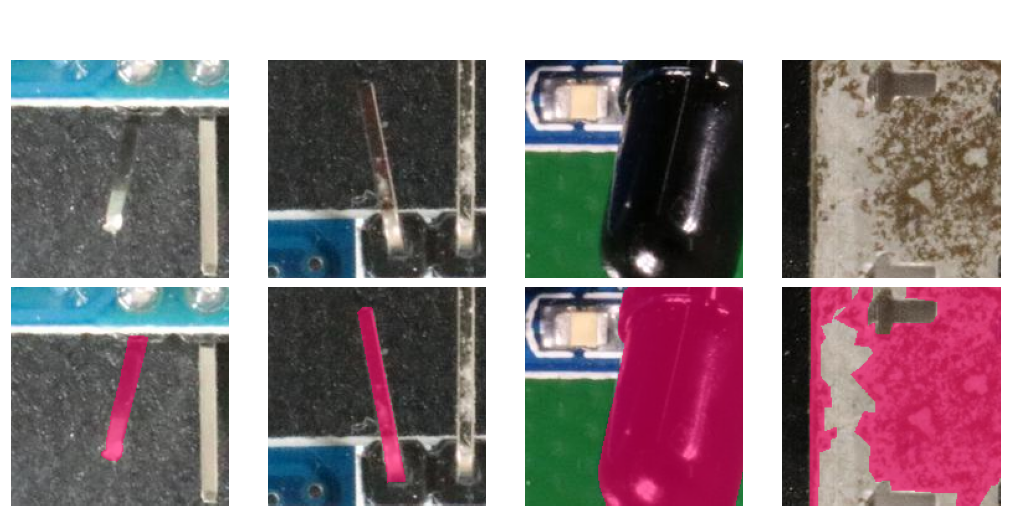

In [7]:
if has_data and "VisA" in cfg["sources"]:
    from src2.tiles import read_mask
    visa_root = Path(cfg["paths"]["VisA"])
    sample = originals[(originals.source == "VisA") & (originals.split == "train") &
                       (originals.label == 1)].groupby("board").head(1)
    available = [r for r in sample.itertuples()
                 if (visa_root / r.path).is_file() and (visa_root / r.annotation).is_file()]
    if available:
        fig, axes = plt.subplots(2, len(available), figsize=(2.45 * len(available), 4.8),
                                 squeeze=False, layout="constrained")
        for j, r in enumerate(available):
            with Image.open(visa_root / r.path) as raw:
                photo = raw.convert("RGB")
            mask = read_mask(visa_root / r.annotation, photo.size)
            y, x = np.argwhere(mask)[int(mask.sum()) // 2]
            crop = (max(0, x-88), max(0, y-88), min(photo.width, x+88), min(photo.height, y+88))
            marked = photo.copy()
            marked.paste(Image.new("RGB", photo.size, "#ff0066"), mask=Image.fromarray(mask.astype("uint8") * 155))
            for ax, view in zip(axes[:, j], [photo.crop(crop), marked.crop(crop)]):
                ax.imshow(view)
                ax.axis("off")
            axes[0, j].set_title(f"{r.board} / {Path(r.path).stem}")
        fig.suptitle("VisA training images   |   raw detail (top), foreground mask (bottom)")
        plt.show()
    else:
        print("VisA의 원본 이미지와 마스크 경로를 확인하세요.")

## 학습 곡선과 최적 체크포인트

A는 DeepPCB, B는 DeepPCB와 PKU, C는 세 출처를 모두 사용해 가중치를 갱신한다. 모든 모델이 같은 validation 원본을 보고 체크포인트와 운영 임계값을 고른다. 학습 loss는 선택한 불균형 보정 방식의 타일 손실이다. 검증은 타일 손실과 원본당 손실을 각각 기록하며, **검증 원본 로그 손실이 가장 낮은 epoch**를 선택한다.

model,train sources,normal tiles,defect tiles,best epoch,val originals,best val image loss
A,DeepPCB,1004,1004,3,1344,1.281
B,DeepPCB + PKU,8189,3980,3,1344,1.160
C,DeepPCB + PKU + VisA,25805,4808,3,1344,0.283


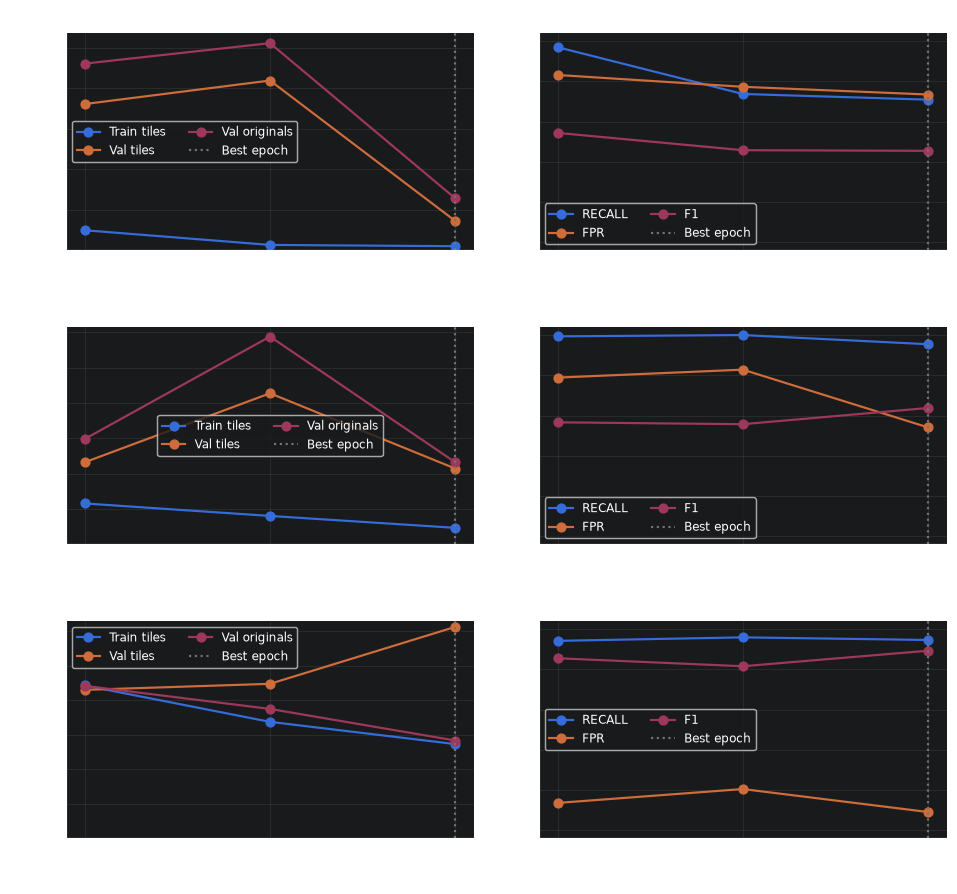

In [8]:
if models:
    rows = []
    fig, axes = plt.subplots(len(models), 2, figsize=(9, 2.8 * len(models)), squeeze=False,
                             layout="constrained")
    for m, (left, right) in zip(models, axes):
        history = read_frame(run_root / m / "history.csv")
        r = info[m]
        rows.append({"model": m, "train sources": " + ".join(r["train_sources"]),
                     "normal tiles": r["train_tiles"]["normal"], "defect tiles": r["train_tiles"]["defect"],
                     "best epoch": r["best_epoch"], "val originals": r["validation_originals"],
                     "best val image loss": r["best_validation_image_log_loss"]})
        series = [("train_loss", "Train tiles"), ("val_tile_loss", "Val tiles"),
                  ("val_image_loss", "Val originals")]
        for field, name in series:
            left.plot(history.epoch, history[field], marker="o", label=name)
        for field in ("recall", "fpr", "f1"):
            right.plot(history.epoch, history["val_" + field], marker="o", label=field.upper())
        left.set(title=f"{m}   Cross-entropy", ylabel="Loss", ylim=(0, None))
        right.set(title=f"{m}   Validation originals at 0.5", ylabel="Fraction", ylim=(-0.04, 1.04))
        for ax in (left, right):
            ax.axvline(r["best_epoch"], color="0.45", linestyle=":", label="Best epoch")
            ax.set(xlabel="Epoch", xticks=history.epoch if len(history) <= 12 else history.epoch.iloc[::len(history)//8])
            ax.grid(alpha=0.15)
            ax.legend(fontsize=8, ncol=2)
    table(pd.DataFrame(rows))
    plt.show()
else:
    print(command("train"))

### Validation에서 결정한 운영 임계값

각 후보에서 불량 recall과 정상 FPR을 계산한다. 정상 FPR 상한 안에서 recall을 최대화하며, 두 목표의 동시 충족 여부를 함께 기록한다. 목표를 충족하지 못한 경우에도 실제 선택 근거와 해당 지표를 표시한다.

A 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 False · Recall target infeasible under the FPR cap. Maximize recall within the cap.
B 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 False · Recall target infeasible under the FPR cap. Maximize recall within the cap.
C 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 False · Recall target infeasible under the FPR cap. Maximize recall within the cap.


model,mode,threshold,n_normal,n_defect,precision,recall,fpr,f1
A,default,0.500,884,460,0.334,0.709,0.734,0.454
A,operating,0.975,884,460,0.835,0.483,0.050,0.612
B,default,0.500,884,460,0.479,0.954,0.541,0.638
B,operating,0.998,884,460,0.878,0.689,0.050,0.772
C,default,0.500,884,460,0.845,0.946,0.090,0.892
C,operating,0.949,884,460,0.899,0.854,0.050,0.876


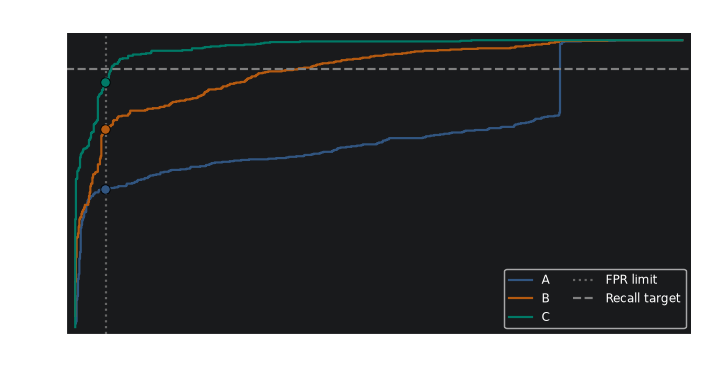

In [9]:
if models:
    rows = []
    for m in models:
        rule = read_json(run_root / m / "threshold.json")
        v = read_frame(run_root / m / "validation/metrics.csv")
        for row in v[v.scope == "all"].itertuples():
            rows.append({"model": m, "mode": row.mode, "threshold": row.threshold,
                         "n_normal": row.n_normal, "n_defect": row.n_defect,
                         "precision": row.precision, "recall": row.recall, "fpr": row.fpr, "f1": row.f1})
        print(m, "목표", rule["policy"], "동시 충족", rule["targets_met"], "·", rule["reason"])
    table(pd.DataFrame(rows))
    fig, ax = plt.subplots(figsize=(6.6, 3.6), layout="constrained")
    for m in models:
        curve = read_frame(run_root / m / "validation/threshold_curve.csv")
        r = read_json(run_root / m / "threshold.json")
        ax.step(curve.fpr, curve.recall, where="post", color=colors[m], label=m)
        if r["validation"]["fpr"] is not None and r["validation"]["recall"] is not None:
            ax.scatter(r["validation"]["fpr"], r["validation"]["recall"], s=42, color=colors[m],
                       edgecolor="black", linewidth=0.6, zorder=4)
    ax.axvline(cfg["threshold"]["max_fpr"], color="0.4", ls=":", label="FPR limit")
    ax.axhline(cfg["threshold"]["min_recall"], color="0.5", ls="--", label="Recall target")
    ax.set(xlim=(-0.015, 1.015), ylim=(-0.025, 1.025), xlabel="False-positive rate",
           ylabel="Defect recall", title="Validation originals   |   dots mark selected thresholds")
    ax.legend(ncol=2, fontsize=8)
    plt.show()

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 노트북을 src2 폴더에서 열었거나 deeppcb 폴더에서 열었을 때 모두 찾습니다.
src2_dir = Path.cwd()
if not (src2_dir / "artifacts" / "runs").exists():
    src2_dir = src2_dir / "src2"

experiment_sources = {
    "A": {"DeepPCB"},
    "B": {"DeepPCB", "PKU"},
    "C": {"DeepPCB", "PKU", "VisA"},
}

prediction_frames = []

for experiment, included_sources in experiment_sources.items():
    predictions_path = (
        src2_dir
        / "artifacts"
        / "runs"
        / experiment
        / "test"
        / "predictions.csv"
    )

    if not predictions_path.exists():
        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {predictions_path}")

    predictions = pd.read_csv(predictions_path)

    required_columns = {
        "source",
        "label",
        "prob_defect",
        "pred_default",
    }
    missing_columns = required_columns - set(predictions.columns)
    if missing_columns:
        raise ValueError(
            f"{predictions_path.name}에 필요한 열이 없습니다: "
            f"{sorted(missing_columns)}"
        )

    # 각 모델의 학습에 포함된 데이터 출처만 평가합니다.
    predictions = predictions[
        predictions["source"].astype(str).isin(included_sources)
    ].copy()

    predictions["experiment"] = experiment
    prediction_frames.append(predictions)

selected_predictions = pd.concat(prediction_frames, ignore_index=True)


def calculate_metrics(frame):
    actual = frame["label"].astype(int).to_numpy()
    predicted = frame["pred_default"].astype(int).to_numpy()
    probability = frame["prob_defect"].astype(float).to_numpy()

    # 라벨 순서를 지정해 정상=0, 불량=1로 혼동행렬을 만듭니다.
    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1],
    ).ravel()

    specificity = tn / (tn + fp) if tn + fp else np.nan
    false_positive_rate = fp / (tn + fp) if tn + fp else np.nan
    false_negative_rate = fn / (fn + tp) if fn + tp else np.nan

    # 평가 구간에 정상과 불량 두 클래스가 모두 있을 때만 계산합니다.
    has_both_classes = len(np.unique(actual)) == 2
    roc_auc = (
        roc_auc_score(actual, probability)
        if has_both_classes else np.nan
    )
    pr_auc = (
        average_precision_score(actual, probability)
        if has_both_classes else np.nan
    )

    return {
        "test 이미지 수": len(frame),
        "정상 수": int((actual == 0).sum()),
        "불량 수": int((actual == 1).sum()),
        "정확도": accuracy_score(actual, predicted),
        "정밀도": precision_score(
            actual, predicted, zero_division=0
        ),
        "재현율": recall_score(
            actual, predicted, zero_division=0
        ),
        "특이도": specificity,
        "F1": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "TN": int(tn),
        "FP(오탐)": int(fp),
        "FN(미검출)": int(fn),
        "TP": int(tp),
        "정상 오탐률": false_positive_rate,
        "불량 미검출률": false_negative_rate,
    }


# 모델별·출처별 지표
source_rows = []

for experiment, included_sources in experiment_sources.items():
    model_predictions = selected_predictions[
        selected_predictions["experiment"] == experiment
    ]

    for source in sorted(included_sources):
        source_predictions = model_predictions[
            model_predictions["source"].astype(str) == source
        ]

        if source_predictions.empty:
            continue

        source_rows.append({
            "모델": experiment,
            "평가 출처": source,
            **calculate_metrics(source_predictions),
        })

source_results = pd.DataFrame(source_rows).sort_values(
    ["모델", "평가 출처"]
).reset_index(drop=True)

print("모델별·출처별 test 결과")
display(source_results.round(4))


# 모델마다 학습에 포함된 출처를 합산한 지표
pooled_rows = []

for experiment in experiment_sources:
    model_predictions = selected_predictions[
        selected_predictions["experiment"] == experiment
    ]

    if model_predictions.empty:
        continue

    pooled_rows.append({
        "모델": experiment,
        "평가 출처": "학습 포함 출처 합산",
        **calculate_metrics(model_predictions),
    })

pooled_results = pd.DataFrame(pooled_rows)

print("모델별 학습 포함 출처 합산 test 결과")
display(pooled_results.round(4))

모델별·출처별 test 결과


,모델,평가 출처,test 이미지 수,정상 수,불량 수,정확도,정밀도,재현율,특이도,F1,ROC-AUC,PR-AUC,TN,FP(오탐),FN(미검출),TP,정상 오탐률,불량 미검출률
0,A,DeepPCB,432,216,216,0.9491,0.9330,0.9676,0.9306,0.9500,0.9902,0.9909,201,15,7,209,0.0694,0.0324
1,B,DeepPCB,432,216,216,0.9676,0.9720,0.9630,0.9722,0.9674,0.9922,0.9930,210,6,8,208,0.0278,0.0370
2,B,PKU,122,2,120,0.9836,0.9836,1.0000,0.0000,0.9917,0.9917,0.9999,0,2,0,120,1.0000,0.0000
3,C,DeepPCB,432,216,216,0.9815,0.9771,0.9861,0.9769,0.9816,0.9983,0.9983,211,5,3,213,0.0231,0.0139
4,C,PKU,122,2,120,0.9836,0.9836,1.0000,0.0000,0.9917,0.8958,0.9981,0,2,0,120,1.0000,0.0000
5,C,VisA,662,602,60,0.9502,0.6957,0.8000,0.9651,0.7442,0.9747,0.8537,581,21,12,48,0.0349,0.2000


모델별 학습 포함 출처 합산 test 결과


,모델,평가 출처,test 이미지 수,정상 수,불량 수,정확도,정밀도,재현율,특이도,F1,ROC-AUC,PR-AUC,TN,FP(오탐),FN(미검출),TP,정상 오탐률,불량 미검출률
0,A,학습 포함 출처 합산,432,216,216,0.9491,0.9330,0.9676,0.9306,0.9500,0.9902,0.9909,201,15,7,209,0.0694,0.0324
1,B,학습 포함 출처 합산,554,218,336,0.9711,0.9762,0.9762,0.9633,0.9762,0.9938,0.9962,210,8,8,328,0.0367,0.0238
2,C,학습 포함 출처 합산,1216,820,396,0.9646,0.9315,0.9621,0.9659,0.9466,0.9950,0.9905,792,28,15,381,0.0341,0.0379


 ## 공통 test 원본 평가

창을 전부 추론한 후 가장 높은 불량 확률을 원본의 점수로 사용한다. 부분 겹침으로 학습에서 제외한 창도 여기에는 들어간다. 기본 0.5와 저장된 운영 임계값은 같은 예측으로 평가한다. 표의 **—**는 정의할 수 없는 값이다. 한 클래스만 있는 구간의 ROC-AUC·PR-AUC와 분모가 0인 비율은 비워 둔다. PR-AUC는 precision–recall 곡선의 사다리꼴 면적이다.

model,mode,threshold,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
A,default,0.500,820,396,0.392,0.305,0.677,0.255,0.420,0.669,0.677,0.745,0.323
A,operating,0.975,820,396,0.808,0.879,0.477,0.968,0.619,0.669,0.677,0.032,0.523
B,default,0.500,820,396,0.616,0.456,0.934,0.462,0.613,0.915,0.902,0.538,0.066
B,operating,0.998,820,396,0.900,0.982,0.705,0.994,0.821,0.915,0.902,0.006,0.295
C,default,0.500,820,396,0.965,0.932,0.962,0.966,0.947,0.995,0.990,0.034,0.038
C,operating,0.949,820,396,0.942,0.988,0.831,0.995,0.903,0.995,0.990,0.005,0.169


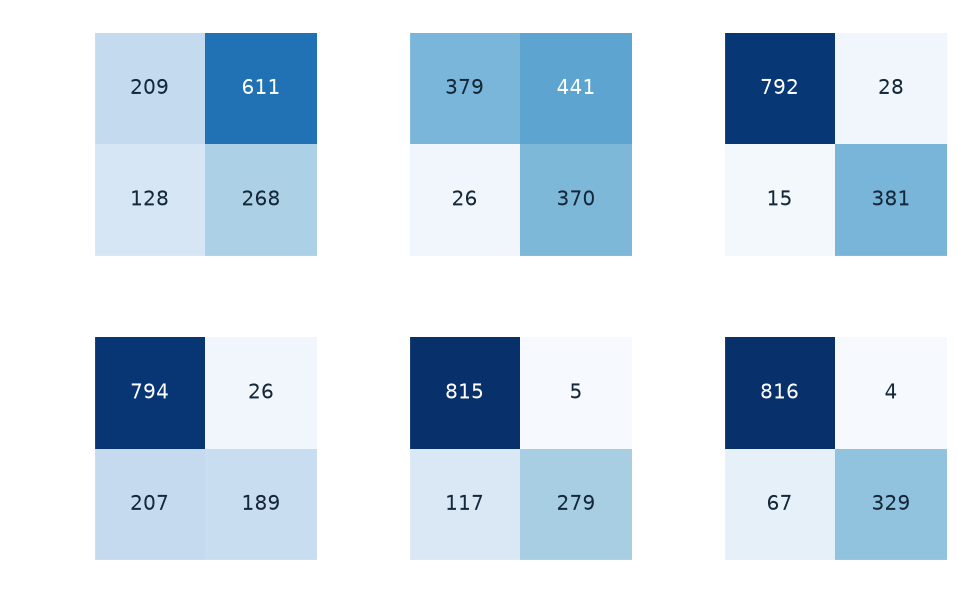

In [11]:
measures = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "fpr", "fnr"]
if tested:
    table(overall[["model", "mode", "threshold", "n_normal", "n_defect", *measures]])
    fig, axes = plt.subplots(2, len(tested), figsize=(3 * len(tested), 5.8),
                             squeeze=False, layout="constrained")
    largest = max(1, int(overall[["tn", "fp", "fn", "tp"]].max().max()))
    for col, m in enumerate(tested):
        for row, mode in enumerate(("default", "operating")):
            result = overall[(overall.model == m) & (overall["mode"] == mode)].iloc[0]
            cm = np.array([[result.tn, result.fp], [result.fn, result.tp]], dtype=int)
            ax = axes[row, col]
            ax.imshow(cm, vmin=0, vmax=largest, cmap="Blues")
            for (i, j), n in np.ndenumerate(cm):
                ax.text(j, i, str(n), ha="center", va="center", fontsize=14,
                        color="white" if n > largest * 0.52 else "#14283a")
            ax.set(xticks=[0, 1], xticklabels=["normal", "defect"], xlabel="Predicted",
                   yticks=[0, 1], yticklabels=["normal", "defect"], ylabel="Actual",
                   title=f"{m}  |  {mode}  {result.threshold:.4f}")
    plt.show()
else:
    print(command("evaluate"))

### 데이터 출처별 성능

표에는 정상·불량 원본 수와 함께 지표를 표시한다. 첫 설정 셀에서 `DETAIL_MODE`를 바꾸면 같은 저장 예측의 다른 임계값 결과를 확인할 수 있다. 각 모델의 `test/metrics.csv`에는 두 모드가 모두 들어 있다.

In [12]:
if tested:
    details = final[final["mode"] == DETAIL_MODE].copy()
    source_rows = details[details.scope.isin(["DeepPCB", "PKU", "VisA"])]
    columns = ["scope", "model", "n_normal", "n_defect", *measures]
    print("출처별 임계값 모드", DETAIL_MODE)
    table(source_rows[columns].sort_values(["scope", "model"]))
    missing = details[details.undefined.notna()]
    if len(missing):
        table(missing[["scope", "model", "n_normal", "n_defect", "undefined"]])

출처별 임계값 모드 operating


scope,model,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
DeepPCB,A,216,216,0.926,0.984,0.866,0.986,0.921,0.990,0.991,0.014,0.134
DeepPCB,B,216,216,0.900,0.994,0.806,0.995,0.890,0.992,0.993,0.005,0.194
DeepPCB,C,216,216,0.949,0.990,0.907,0.991,0.947,0.998,0.998,0.009,0.093
PKU,A,2,120,0.016,—,0.000,1.000,0.000,0.725,0.994,0.000,1.000
PKU,B,2,120,0.877,1.000,0.875,1.000,0.933,0.992,1.000,0.000,0.125
PKU,C,2,120,0.885,0.991,0.892,0.500,0.939,0.896,0.998,0.500,0.108
VisA,A,602,60,0.878,0.080,0.033,0.962,0.047,0.426,0.078,0.038,0.967
VisA,B,602,60,0.903,0.000,0.000,0.993,0.000,0.487,0.088,0.007,1.000
VisA,C,602,60,0.947,0.963,0.433,0.998,0.598,0.975,0.853,0.002,0.567


scope,model,n_normal,n_defect,undefined
PKU,A,2,120,precision
VisA/pcb3,A,151,15,precision
VisA/pcb1,B,150,15,precision
VisA/pcb2,B,150,15,precision
VisA/pcb3,B,151,15,precision


### VisA PCB1~PCB4

원본 기준으로 PCB 종류별 결과를 나눈다. 불량 원본 수가 작을 때는 미검출 몇 건만으로도 recall이 크게 움직인다.

scope,model,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
VisA/pcb1,A,150,15,0.915,1.000,0.067,1.000,0.125,0.665,0.265,0.000,0.933
VisA/pcb1,B,150,15,0.909,—,0.000,1.000,0.000,0.586,0.201,0.000,1.000
VisA/pcb1,C,150,15,0.939,1.000,0.333,1.000,0.500,0.990,0.932,0.000,0.667
VisA/pcb2,A,150,15,0.891,0.000,0.000,0.980,0.000,0.289,0.059,0.020,1.000
VisA/pcb2,B,150,15,0.909,—,0.000,1.000,0.000,0.410,0.077,0.000,1.000
VisA/pcb2,C,150,15,0.970,0.917,0.733,0.993,0.815,0.972,0.885,0.007,0.267
VisA/pcb3,A,151,15,0.910,—,0.000,1.000,0.000,0.457,0.150,0.000,1.000
VisA/pcb3,B,151,15,0.910,—,0.000,1.000,0.000,0.474,0.078,0.000,1.000
VisA/pcb3,C,151,15,0.940,1.000,0.333,1.000,0.500,0.990,0.915,0.000,0.667
VisA/pcb4,A,151,15,0.795,0.048,0.067,0.868,0.056,0.250,0.057,0.132,0.933


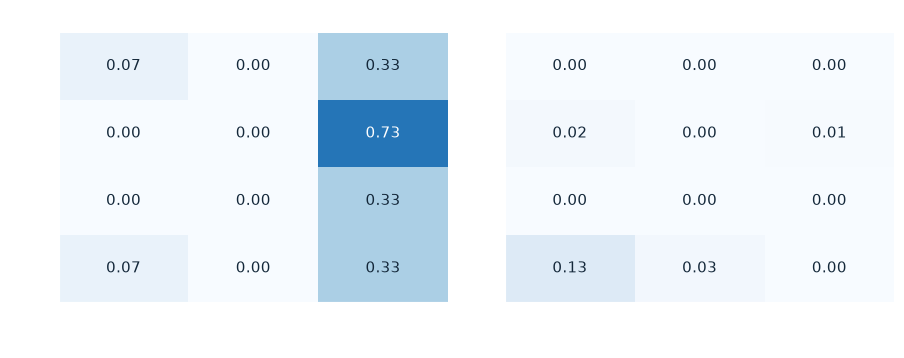

In [13]:
if tested:
    boards = details[details.scope.str.startswith("VisA/")]
    table(boards[columns].sort_values(["scope", "model"]))
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), layout="constrained")
    for ax, metric, title in zip(axes, ["recall", "fpr"], ["Defect recall", "Normal FPR"]):
        matrix = boards.pivot(index="scope", columns="model", values=metric).reindex(columns=tested)
        values = matrix.to_numpy(float)
        ax.imshow(np.ma.masked_invalid(values), cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for (i, j), n in np.ndenumerate(values):
            ax.text(j, i, "—" if np.isnan(n) else f"{n:.2f}", ha="center", va="center",
                    color="white" if n > 0.55 else "#14283a")
        ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
               yticks=range(len(matrix)), yticklabels=[s.split("/")[-1] for s in matrix.index],
               xlabel="Training experiment", title=f"{title}   |   {DETAIL_MODE}")
    plt.show()

## 정상 오탐과 불량 미검출 사례

저장된 test 예측에서 정상 오탐은 불량 점수가 높은 순, 불량 미검출은 낮은 순으로 최대 세 장씩 표시한다. 청록색 창은 원본 점수를 결정한 입력 타일이다. 각 행의 원본 경로와 확률로 사례를 다시 확인할 수 있다.

사례 모델 및 임계값 모드 C operating


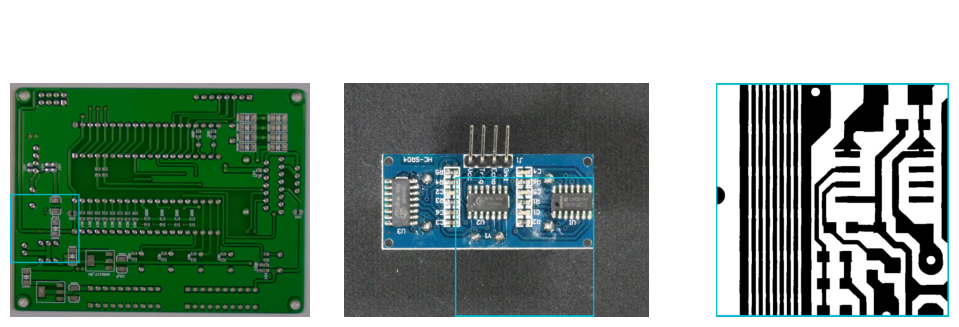

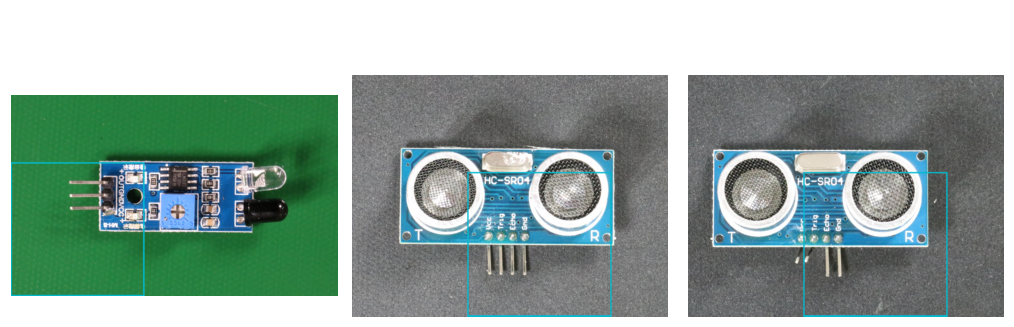

error,image_id,label,prob_defect,max_tile_id
False positive,PKU/PCB_USED/09.JPG,0,0.996,3158
False positive,VisA/pcb2/Data/Images/Normal/0653.JPG,0,0.977,31136
False positive,DeepPCB/group13000/13000/13000005_temp.jpg,0,0.968,968
False negative,VisA/pcb3/Data/Images/Anomaly/072.JPG,1,0.157,33655
False negative,VisA/pcb1/Data/Images/Anomaly/081.JPG,1,0.171,20480
False negative,VisA/pcb1/Data/Images/Anomaly/004.JPG,1,0.179,20018


In [14]:
if tested and has_data:
    model = ERROR_MODEL if ERROR_MODEL in tested else tested[-1]
    pred = read_frame(run_root / model / "test/predictions.csv")
    decision = pred["pred_" + DETAIL_MODE]
    cases = pd.concat([
        pred[(pred.label == 0) & (decision == 1)].nlargest(3, "prob_defect").assign(error="False positive"),
        pred[(pred.label == 1) & (decision == 0)].nsmallest(3, "prob_defect").assign(error="False negative")])
    print("사례 모델 및 임계값 모드", model, DETAIL_MODE)
    tile_lookup = tiles.set_index("tile_id")
    for error in ("False positive", "False negative"):
        examples = cases[cases.error == error]
        if examples.empty:
            print(error, "사례 0장")
            continue
        fig, axes = plt.subplots(1, len(examples), figsize=(3.2 * len(examples), 3),
                                 layout="constrained", squeeze=False)
        for ax, r in zip(axes[0], examples.itertuples()):
            path = Path(cfg["paths"][r.source]) / r.path
            if path.is_file():
                with Image.open(path) as raw:
                    image = raw.convert("RGB")
                tile = tile_lookup.loc[r.max_tile_id]
                box = (int(tile.x0), int(tile.y0), int(tile.x1)-1, int(tile.y1)-1)
                ImageDraw.Draw(image).rectangle(box, outline="#00bad1", width=max(4, image.width // 220))
                image.thumbnail((540, 420))
                ax.imshow(image)
            else:
                ax.text(0.5, 0.5, "Source image unavailable", ha="center")
            ax.set_title(f"{r.source} / {r.board}\nP(defect) {r.prob_defect:.4f}")
            ax.axis("off")
        fig.suptitle(f"{model}   |   {error}")
        plt.show()
    table(cases[["error", "image_id", "label", "prob_defect", "max_tile_id"]])
else:
    print("원본과 저장된 test 예측이 있어야 사례를 표시합니다.")

## A/B/C 비교와 해석

동일 원본 집합에서 출처를 추가했을 때의 차이를 퍼센트포인트로 계산한다. 운영 임계값 표에는 각 모델의 검증 단계에서 정한 값이 적용된다.

In [15]:
if tested:
    delta_rows = []
    for first, second in (("A", "B"), ("B", "C")):
        if first not in tested or second not in tested:
            continue
        for scope in ("all", "DeepPCB", "PKU", "VisA"):
            pair = details[details.scope == scope].set_index("model")
            delta_rows.append({"model change": f"{first} → {second}", "scope": scope,
                               "Δ recall (pp)": 100 * (pair.loc[second, "recall"] - pair.loc[first, "recall"]),
                               "Δ FPR (pp)": 100 * (pair.loc[second, "fpr"] - pair.loc[first, "fpr"])})
    if delta_rows:
        table(pd.DataFrame(delta_rows))
    for r in compact.itertuples():
        print(f"{r.model} · 불량 {r.n_defect}장 중 {r.fn}장 미검출, 정상 {r.n_normal}장 중 {r.fp}장 오탐.")
    if len(tested) > 1:
        current = source_rows[source_rows.model == tested[-1]].dropna(subset=["recall"])
        if len(current):
            r = current.loc[current.recall.idxmin()]
            display(Markdown(f"**{tested[-1]}의 출처별 최저 recall은 {r.scope}의 {r.recall:.1%}**였다. "
                             f"이 출처의 불량 {int(r.n_defect)}장 중 {int(r.fn)}장을 놓쳤다. "
                             "합산 점수에는 출처마다 다른 표본 수가 반영된다."))
    if has_data:
        pku_test = counts[(counts.source == "PKU") & (counts.split == "test")]
        if not pku_test.empty:
            n = int(pku_test.iloc[0].original_normal)
            print(f"PKU test 정상은 {n}장이다." + (f" 오탐 한 장이 FPR을 {100/n:.1f}%p 바꾼다." if n else " FPR은 정의되지 않는다."))

model change,scope,Δ recall (pp),Δ FPR (pp)
A → B,all,22.727,-2.561
A → B,DeepPCB,-6.019,-0.926
A → B,PKU,87.500,0.000
A → B,VisA,-3.333,-3.156
B → C,all,12.626,-0.122
B → C,DeepPCB,10.185,0.463
B → C,PKU,1.667,50.000
B → C,VisA,43.333,-0.498


A · 불량 396장 중 207장 미검출, 정상 820장 중 26장 오탐.
B · 불량 396장 중 117장 미검출, 정상 820장 중 5장 오탐.
C · 불량 396장 중 67장 미검출, 정상 820장 중 4장 오탐.


**C의 출처별 최저 recall은 VisA의 43.3%**였다. 이 출처의 불량 60장 중 34장을 놓쳤다. 합산 점수에는 출처마다 다른 표본 수가 반영된다.

PKU test 정상은 2장이다. 오탐 한 장이 FPR을 50.0%p 바꾼다.


## 실행 순서와 한계

1. 설정 파일의 데이터 경로를 확인하고 `python -m src2.01_prepare`로 분할과 라벨 미리보기를 만든다.
2. `python -m src2.02_train --experiments A B C`로 학습한다. validation에서 선택한 체크포인트·임계값·목표 달성 여부를 확인한다.
3. 조건을 확정한 뒤 `python -m src2.03_evaluate --experiments A B C`를 한 번 실행하고 이 노트북을 위에서 아래로 실행한다.

DeepPCB와 PKU는 보드 그룹·템플릿 번호의 수가 작다. VisA는 각 종류 안에서 원본 이미지 ID 기준으로 나뉘므로 같은 PCB 제품 종류가 여러 분할에 등장한다. SHA-256은 파일 바이트의 중복을 검사하며 재인코딩한 유사 이미지를 식별하려면 별도 정보가 필요하다.

각 모델의 학습 데이터 규모와 epoch당 업데이트 횟수는 달라진다. 결과는 설정과 seed가 하나인 비교다. 여러 타일 중 최댓값을 취하면 타일 수가 많은 원본의 오탐 가능성도 달라진다. 운영 목표는 validation에서 설정했으며 시험에서 관찰한 오탐·미검출 사례는 최종 성능을 설명하는 데 사용했다.